# Data Ingestion

In [2312]:
import pandas as pd
import os
from pathlib import Path
import glob

In [2313]:
# Dictionary for model name mapping
MODEL_NAME_MAPPING = {
    'x-ai/grok-4-fast': 'Grok',
    'openai/gpt-5-nano': 'ChatGPT',
    'google/gemini-2.5-flash': 'Gemini',
    'deepseek/deepseek-chat-v3.1': 'DeepSeek'
}

In [2314]:
# Define strategy directories
strategies = {
    'strategy_one': 'strategy_one_results',
    'strategy_two': 'strategy_two_results',
    'strategy_three': 'strategy_three_results',
    'strategy_four': 'strategy_four_results'
}


In [2315]:

# List to hold all dataframes
all_dfs = []

# Read files from each strategy directory
for strategy_name, directory in strategies.items():
    dir_path = os.path.join('.', directory)
    
    # Check if directory exists
    if not os.path.exists(dir_path):
        print(f"Warning: Directory '{dir_path}' not found. Skipping...")
        continue
    
    # Find all CSV files matching the pattern results_*.csv
    csv_files = glob.glob(os.path.join(dir_path, 'results_*.csv'))
    
    if not csv_files:
        print(f"Warning: No CSV files found in '{dir_path}'. Skipping...")
        continue
    
    # Read each CSV file in the directory
    for csv_file in csv_files:
        # Extract model name from filename
        filename = os.path.basename(csv_file)
        model_identifier = filename.replace('results_', '').replace('.csv', '')
        
        # Read the CSV
        df = pd.read_csv(csv_file)
        
        # Add strategy column
        df['strategy'] = strategy_name
        
        all_dfs.append(df)
        print(f"✓ Loaded: {csv_file} ({len(df)} rows)")


✓ Loaded: ./strategy_one_results/results_deepseek_deepseek-chat-v3.1.csv (144 rows)
✓ Loaded: ./strategy_one_results/results_x-ai_grok-4-fast.csv (144 rows)
✓ Loaded: ./strategy_one_results/results_openai_gpt-5-nano.csv (144 rows)
✓ Loaded: ./strategy_one_results/results_google_gemini-2.5-flash.csv (144 rows)
✓ Loaded: ./strategy_two_results/results_deepseek_deepseek-chat-v3.1.csv (432 rows)
✓ Loaded: ./strategy_two_results/results_x-ai_grok-4-fast.csv (432 rows)
✓ Loaded: ./strategy_two_results/results_openai_gpt-5-nano.csv (432 rows)
✓ Loaded: ./strategy_two_results/results_google_gemini-2.5-flash.csv (432 rows)
✓ Loaded: ./strategy_three_results/results_deepseek_deepseek-chat-v3.1.csv (432 rows)
✓ Loaded: ./strategy_three_results/results_x-ai_grok-4-fast.csv (432 rows)
✓ Loaded: ./strategy_three_results/results_openai_gpt-5-nano.csv (432 rows)
✓ Loaded: ./strategy_three_results/results_google_gemini-2.5-flash.csv (432 rows)
✓ Loaded: ./strategy_four_results/results_deepseek_deepseek

In [2316]:

# Combine all dataframes
if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    print(f"\n{'='*60}")
    print(f"Successfully combined {len(all_dfs)} files")
    print(f"Total rows: {len(combined_df)}")
    print(f"{'='*60}")
    results_df = combined_df
else:
    print("No data files were found or loaded.")


Successfully combined 16 files
Total rows: 5184


In [2317]:
results_df['model'] = results_df['model'].replace(MODEL_NAME_MAPPING)

In [2318]:
results_df['npi_preference'] = results_df['npi_level_selected'] - results_df['npi_level_non_selected']

In [2319]:
results_df['infection_preference'] = results_df['infection_rate_selected'] - results_df['infection_rate_non_selected']

In [2320]:
results_df['irrational_choice'] = (
    ((results_df['infection_rate_selected'] > results_df['infection_rate_non_selected']) & 
     (results_df['npi_level_selected'] >= results_df['npi_level_non_selected'])) |
    ((results_df['npi_level_selected'] > results_df['npi_level_non_selected']) & 
    (results_df['infection_rate_selected'] <= results_df['infection_rate_non_selected']))
)

# Analysis

### Figure 1: % Irrational Choice By Strategy

##### Pre-processing + Function definition

In [2321]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


In [2322]:

# Set style with larger fonts
sns.set_style("white")  # Changed from "whitegrid" to remove grid
sns.set_context("paper", font_scale=2.8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 300


In [2323]:

# Calculate irrational choice frequency by model and strategy
def calculate_irrational_frequency(df):
    """
    Calculate the frequency of irrational choices for each model in each strategy.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing 'model', 'strategy', and 'irrational_choice' columns
    
    Returns:
    --------
    pd.DataFrame
        DataFrame with irrational choice rates by strategy and model
    """
    # Group by strategy and model, calculate mean of irrational_choice
    freq_data = df.groupby(['strategy', 'model'])['irrational_choice'].agg([
        ('irrational_rate', 'mean'),
        ('total_choices', 'count')
    ]).reset_index()
    
    # Convert to percentage
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100
    
    return freq_data


In [2324]:

def extract_strategy_number(strategy_name):
    """
    Extract the numeric value from a strategy name for proper sorting.
    Handles various formats like 'strategy_one', 'strategy_1', 'Strategy One', etc.
    """
    # Map word numbers to integers
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    
    strategy_lower = strategy_name.lower()
    
    # First, try to find a direct number
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    
    # If no digits, look for word numbers
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    
    # Default to 0 if no number found
    return 0



In [2325]:

# Calculate frequencies
irrational_freq = calculate_irrational_frequency(results_df)


In [2326]:

# Individual Strategy Plots
# Create separate publication-ready bar graphs for each strategy.

def plot_individual_strategies(freq_data, save_figures=False):
    """
    Create individual publication-ready bar plots for each strategy using Seaborn.
    Models are ordered by irrational choice rate (highest to lowest).
    
    Parameters:
    -----------
    freq_data : pd.DataFrame
        DataFrame with strategy, model, and irrational_percentage columns
    save_figures : bool
        Whether to save figures to disk
    """
    # Sort strategies numerically using proper extraction
    strategies = sorted(freq_data['strategy'].unique(), 
                       key=extract_strategy_number)
    
    # Define color palette
    models = sorted(freq_data['model'].unique())
    palette = sns.color_palette("Set2", n_colors=len(models))
    model_colors = dict(zip(models, palette))
    
    # Create individual plots for each strategy
    for strategy in strategies:
        strategy_data = freq_data[freq_data['strategy'] == strategy].copy()
        
        # Sort models by irrational percentage (highest to lowest)
        strategy_data = strategy_data.sort_values('irrational_percentage', ascending=False)
        
        fig, ax = plt.subplots(figsize=(14, 8))
        
        # Create bar plot with Seaborn
        bars = sns.barplot(
            data=strategy_data,
            x='model',
            y='irrational_percentage',
            palette=[model_colors[m] for m in strategy_data['model']],
            edgecolor='black',
            linewidth=1.8,
            ax=ax
        )
        
        # Add value labels on bars
        for i, bar in enumerate(bars.patches):
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2., 
                height + 0.5,
                f'{height:.1f}%',
                ha='center', 
                va='bottom',
                fontsize=32,
                fontweight='bold'
            )
        
        # Formatting
        ax.set_xlabel('Model', fontsize=18, fontweight='bold', labelpad=12)
        ax.set_ylabel('Irrational Choice Rate (%)', fontsize=18, fontweight='bold', labelpad=12)
        
        # Format strategy name for title
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(f'Irrational Choice Rate by Model\n{strategy_title}', 
                     fontsize=20, fontweight='bold', pad=20)
        
        # Set y-axis limits with padding
        max_val = strategy_data['irrational_percentage'].max()
        ax.set_ylim(0, min(100, max_val * 1.25))
        
        # Adjust tick parameters
        ax.tick_params(axis='x', labelsize=16, rotation=0)
        ax.tick_params(axis='y', labelsize=16)
        
        # Remove all spines for cleaner look
        sns.despine(ax=ax)
        
        plt.tight_layout()
        
        if save_figures:
            plt.savefig(f'irrational_choices_{strategy}.png', dpi=300, bbox_inches='tight', facecolor='white')
        
        plt.show()



In [2327]:

# Generate individual strategy plots
# plot_individual_strategies(irrational_freq, save_figures=False)



In [2328]:

def plot_combined_strategies(freq_data, save_figure=False):
    """
    Create a combined publication-ready multi-panel plot with all strategies.
    Strategies are displayed in numerical order (Strategy One, Two, Three, Four, etc.).
    Models within each panel are ordered by irrational choice rate (highest to lowest).
    
    Parameters:
    -----------
    freq_data : pd.DataFrame
        DataFrame with strategy, model, and irrational_percentage columns
    save_figure : bool
        Whether to save figure to disk
    """
    # Sort strategies numerically using proper extraction
    strategies = sorted(freq_data['strategy'].unique(), 
                       key=extract_strategy_number)
    n_strategies = len(strategies)
    
    # Determine grid layout (2 columns, dynamic rows)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    # Define color palette
    models = sorted(freq_data['model'].unique())
    palette = sns.color_palette("Set2", n_colors=len(models))
    model_colors = dict(zip(models, palette))
    
    # Create figure with subplots - scale size based on number of rows
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 9 * n_rows))
    
    # Flatten axes array for easier iteration
    if n_strategies == 1:
        axes = np.array([axes])
    elif n_strategies <= 2:
        axes = np.array(axes) if isinstance(axes, np.ndarray) else np.array([axes])
        if axes.ndim == 1:
            axes = axes.flatten()
    else:
        axes = axes.flatten()
    
    # Plot each strategy IN NUMERICAL ORDER
    for idx, strategy in enumerate(strategies):
        ax = axes[idx]
        strategy_data = freq_data[freq_data['strategy'] == strategy].copy()
        
        # Sort models by irrational percentage (highest to lowest) within this strategy
        strategy_data = strategy_data.sort_values('irrational_percentage', ascending=False)
        
        # Create bar plot using ordered data
        bars = ax.bar(
            range(len(strategy_data)),
            strategy_data['irrational_percentage'],
            color=[model_colors[m] for m in strategy_data['model']],
            edgecolor='black',
            linewidth=1.8
        )
        
        # Set x-axis labels to model names
        ax.set_xticks(range(len(strategy_data)))
        ax.set_xticklabels(strategy_data['model'], rotation=0, ha='center') 
        
        # Add value labels on bars
        for i, (bar, val) in enumerate(zip(bars, strategy_data['irrational_percentage'])):
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2., 
                height + 0.5,
                f'{val:.1f}%',
                ha='center', 
                va='bottom',
                fontsize=20, # font size adjustment
                fontweight='bold'
            )
        
        # Formatting
        ax.set_xlabel('Model', fontsize=20, fontweight='bold', labelpad=10)# font size adjustment
        ax.set_ylabel('Irrational Choice Rate (%)', fontsize=20, fontweight='bold', labelpad=10)# font size adjustment
        
        # Format strategy name for title (NO panel labels)
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(strategy_title, fontsize=24, fontweight='bold', pad=15) # font size adjustment
        
        # Set y-axis limits with padding
        max_val = freq_data['irrational_percentage'].max()
        ax.set_ylim(0, min(100, max_val * 1.25))
        
        # Adjust tick parameters
        ax.tick_params(axis='x', labelsize=20) # font size adjustment
        ax.tick_params(axis='y', labelsize=20) # font size adjustment
        
        # Remove all spines
        sns.despine(ax=ax)
    
    # Hide unused subplots
    for idx in range(n_strategies, len(axes)):
        axes[idx].set_visible(False)
    
    # Overall title
    fig.suptitle('Irrational Choice Rates by Model and Strategy', 
                 fontsize=32, fontweight='bold', y=0.995) # font size adjustment
    
    plt.tight_layout()
    
    if save_figure:
        plt.savefig('irrational_choices_combined.png', dpi=300, bbox_inches='tight', facecolor='white')
    
    plt.show()



##### Figure Output

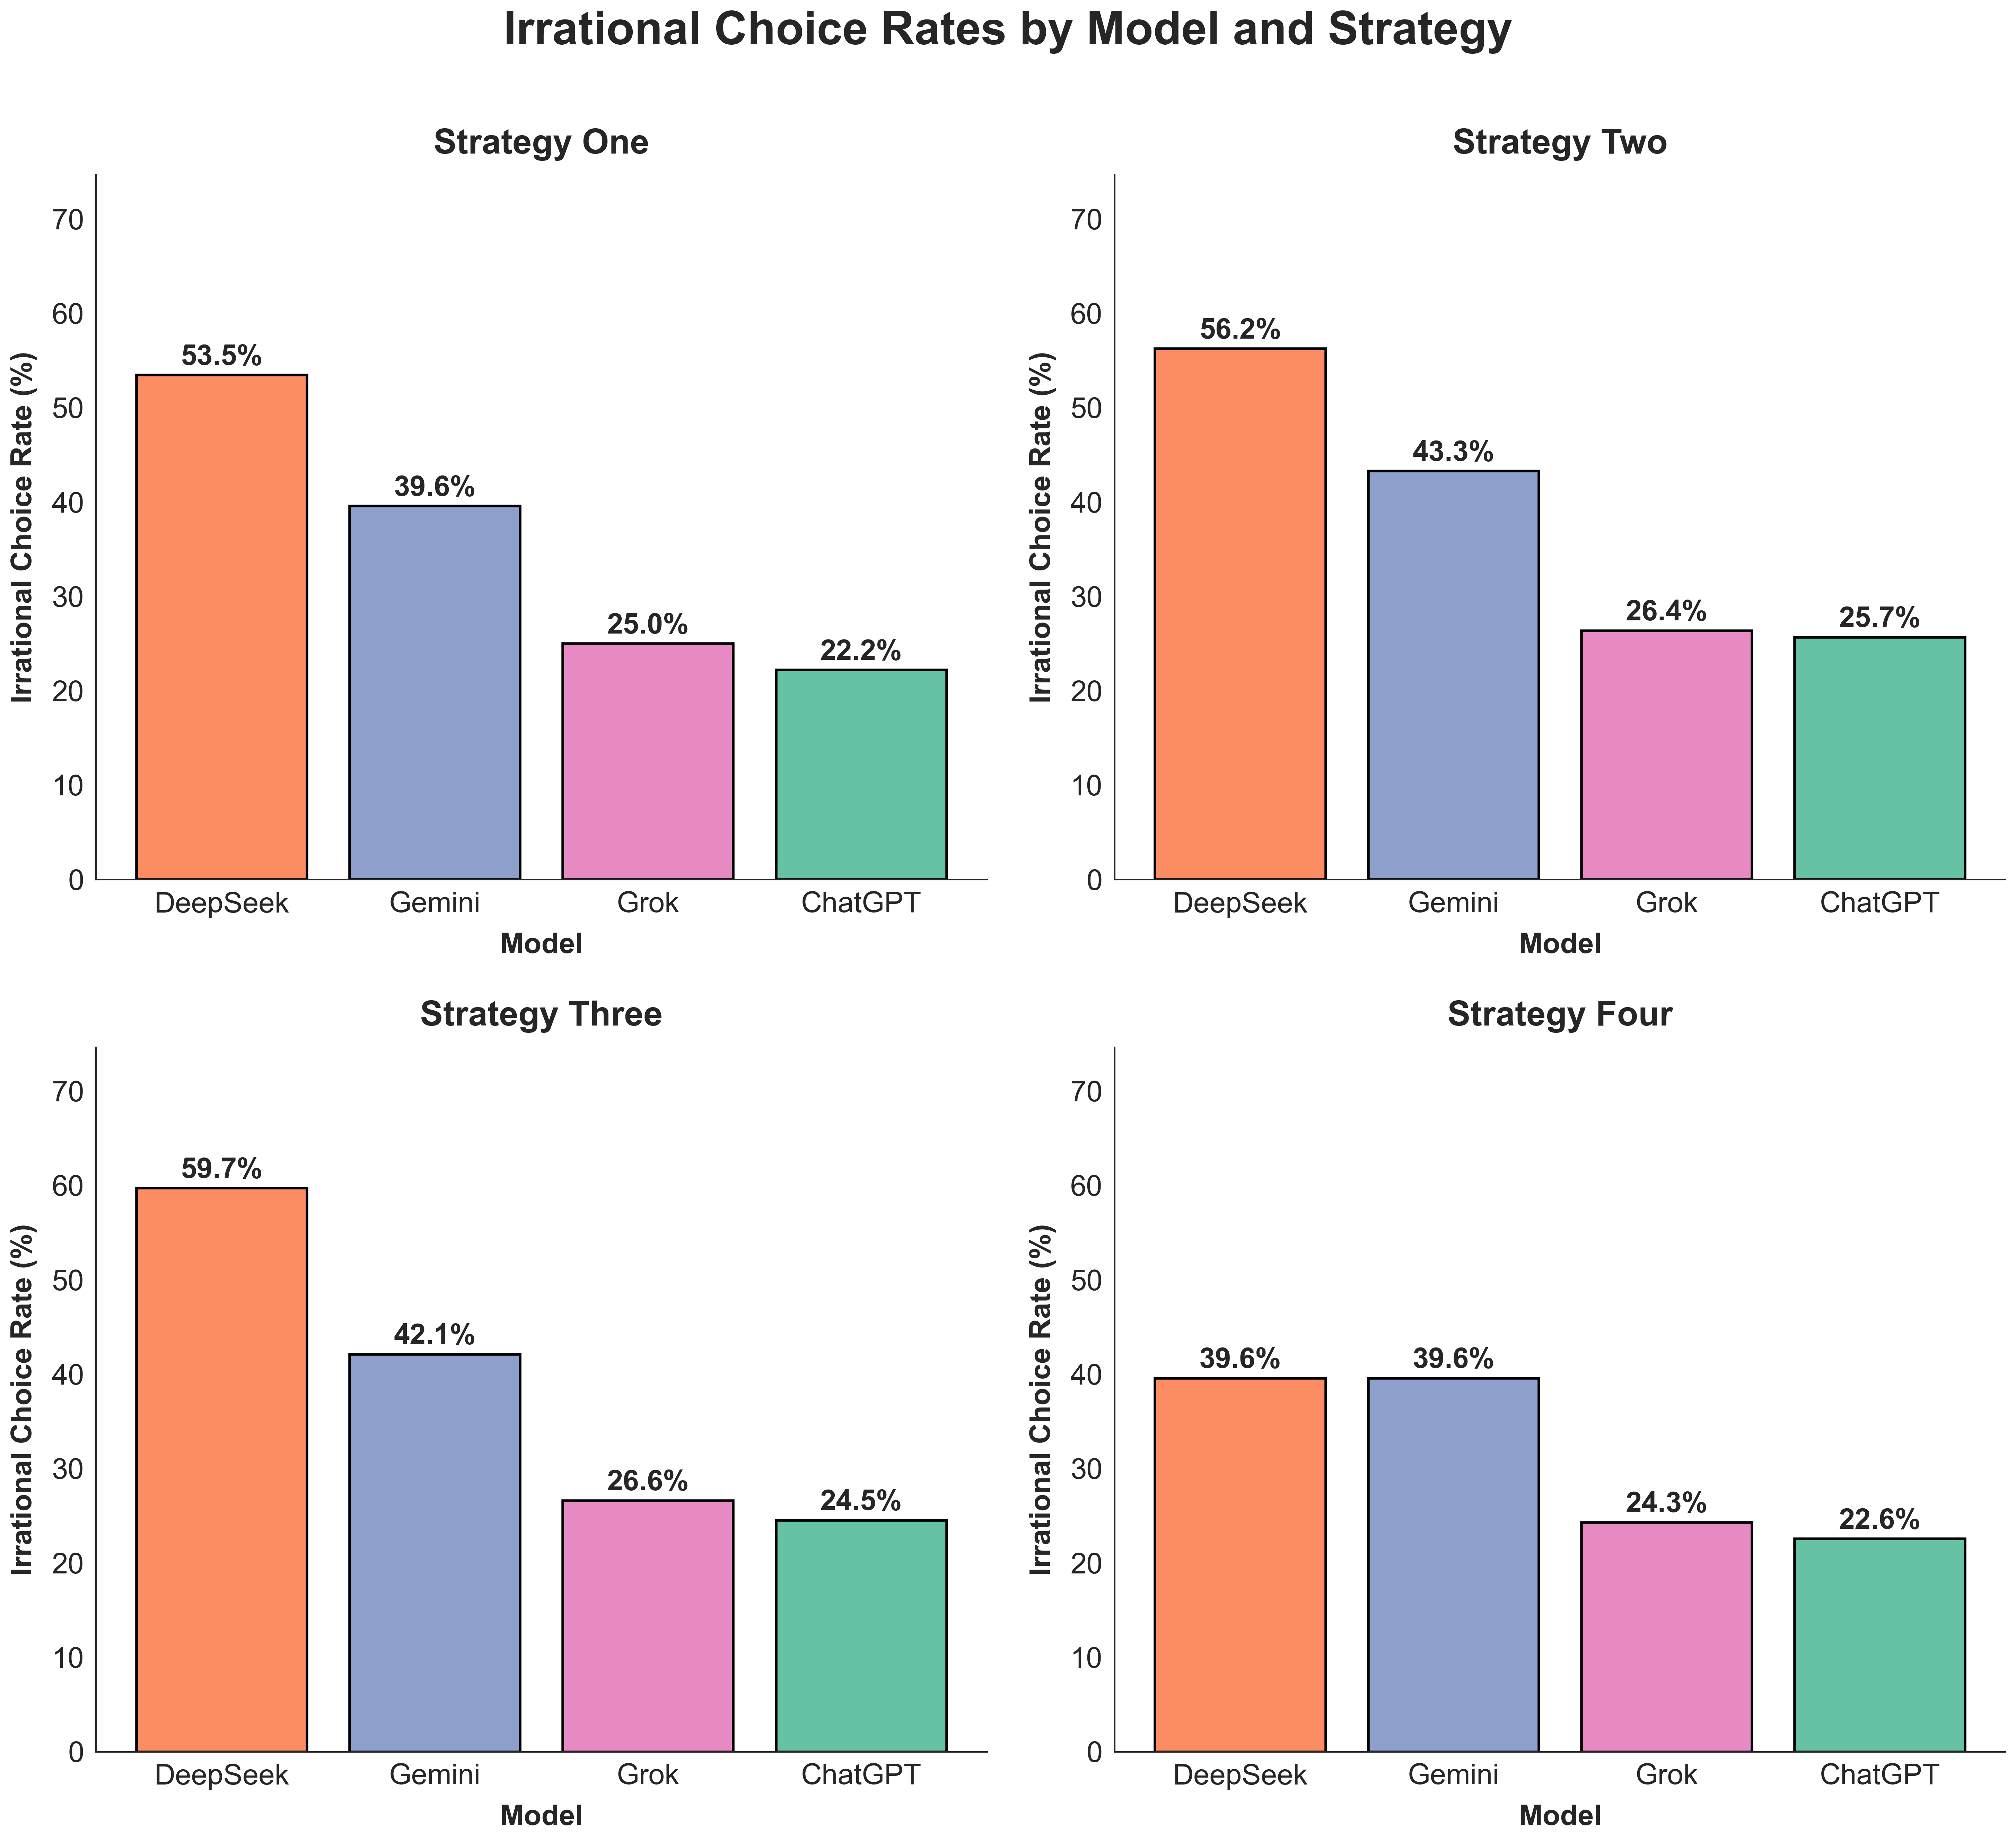

In [2329]:
# Generate combined multi-panel plot with proper ordering
plot_combined_strategies(irrational_freq, save_figure=False)

### Figure 2: % Irrational Choice By Strategy (context-stratified)

##### Pre-Processing + Function Definition

In [2330]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


In [2331]:

# Set publication-ready style
sns.set_style("white")
sns.set_context("paper", font_scale=1.8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 300


In [2332]:

def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    
    strategy_lower = strategy_name.lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    
    return 0


In [2333]:

def get_context_column(strategy_name):
    """Return the appropriate context column name for each strategy."""
    strategy_num = extract_strategy_number(strategy_name)
    
    context_mapping = {
        2: 'capacity_context',
        3: 'economic_context',
        4: 'user_preference_type'
    }
    
    return context_mapping.get(strategy_num, None)


In [2334]:

def get_legend_title(context_col):
    """Return a formatted legend title based on the context column name."""
    if not context_col:
        return None
    
    title_mapping = {
        'capacity_context': 'Capacity Context',
        'economic_context': 'Economic Context',
        'user_preference_type': 'User Preference'
    }
    
    return title_mapping.get(context_col, context_col.replace('_', ' ').title())


In [2335]:

def calculate_context_breakdown(df):
    """Calculate irrational choice rates broken down by context within each strategy."""
    results = []
    
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    
    for strategy in strategies:
        strategy_data = df[df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        
        if context_col and context_col in strategy_data.columns:
            # Group by model and context
            grouped = strategy_data.groupby(['model', context_col])['irrational_choice'].agg([
                ('irrational_rate', 'mean'),
                ('count', 'count')
            ]).reset_index()
            
            grouped['irrational_percentage'] = grouped['irrational_rate'] * 100
            grouped['strategy'] = strategy
            grouped['context_type'] = context_col
            
            results.append(grouped)
        else:
            # Strategy 1 or missing context - overall rate
            grouped = strategy_data.groupby('model')['irrational_choice'].agg([
                ('irrational_rate', 'mean'),
                ('count', 'count')
            ]).reset_index()
            
            grouped['irrational_percentage'] = grouped['irrational_rate'] * 100
            grouped['strategy'] = strategy
            grouped['context_type'] = 'overall'
            grouped['context'] = 'Overall'
            
            results.append(grouped)
    
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


In [2336]:

# Calculate context breakdowns
context_breakdown = calculate_context_breakdown(results_df)


In [2337]:

def plot_strategy_grouped_by_context(breakdown_data, save_figures=False):
    """
    Create individual plots for each strategy with grouped bars by context.
    Each model has multiple bars (one per context) with different colors.
    """
    strategies = sorted(breakdown_data['strategy'].unique(), key=extract_strategy_number)
    
    for strategy in strategies:
        strategy_data = breakdown_data[breakdown_data['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        strategy_num = extract_strategy_number(strategy)
        
        if not context_col:
            context_col = 'context'
        
        # Get unique models and contexts
        models = sorted(strategy_data['model'].unique())
        contexts = sorted(strategy_data[context_col].unique())
        
        # Create color palette for contexts
        palette = sns.color_palette("Set2", n_colors=len(contexts))
        context_colors = dict(zip(contexts, palette))
        
        # Set up the bar positions
        x = np.arange(len(models))
        width = 0.8 / len(contexts)  # Width of each bar
        
        fig, ax = plt.subplots(figsize=(14, 8))
        
        # Plot bars for each context
        for i, context in enumerate(contexts):
            context_data = strategy_data[strategy_data[context_col] == context].copy()
            context_data = context_data.set_index('model').reindex(models).reset_index()
            
            # Calculate positions for this context's bars
            positions = x + (i - len(contexts)/2 + 0.5) * width
            
            bars = ax.bar(
                positions,
                context_data['irrational_percentage'],
                width,
                label=str(context).replace('_', ' ').title(),
                color=context_colors[context],
                edgecolor='black',
                linewidth=1.5
            )
            
            # Add value labels on bars
            for bar, val in zip(bars, context_data['irrational_percentage']):
                if not pd.isna(val):
                    height = bar.get_height()
                    ax.text(
                        bar.get_x() + bar.get_width()/2., 
                        height + 0.5,
                        f'{val:.1f}%',
                        ha='center', 
                        va='bottom',
                        fontsize=12,
                        fontweight='bold'
                    )
        
        # Formatting
        ax.set_xlabel('Model', fontsize=18, fontweight='bold', labelpad=12)
        ax.set_ylabel('Irrational Choice Rate (%)', fontsize=18, fontweight='bold', labelpad=12)
        
        # Format strategy name for title
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(f'{strategy_title}', fontsize=20, fontweight='bold', pad=20)
        
        # Set x-axis labels
        ax.set_xticks(x)
        ax.set_xticklabels(models, fontsize=16)
        
        # Set y-axis limits
        ax.set_ylim(0, min(100, strategy_data['irrational_percentage'].max() * 1.3))
        
        # Adjust ticks
        ax.tick_params(axis='y', labelsize=16)
        
        # Add legend only for strategies 2, 3, 4 (not strategy 1)
        if strategy_num != 1:
            legend_title = get_legend_title(context_col)
            ax.legend(
                title=legend_title,
                loc='upper right', 
                fontsize=14, 
                title_fontsize=15,
                frameon=True, 
                fancybox=True, 
                shadow=True
            )
        
        # Remove spines
        sns.despine(ax=ax)
        
        plt.tight_layout()
        
        if save_figures:
            plt.savefig(f'irrational_choices_{strategy}_grouped.png', 
                       dpi=300, bbox_inches='tight', facecolor='white')
        
        plt.show()

# Generate grouped bar plots for each strategy
# plot_strategy_grouped_by_context(context_breakdown, save_figures=False)


In [2338]:

def plot_combined_grouped_contexts(breakdown_data, save_figure=False):
    """
    Create a combined 4-panel figure with grouped bars by context for each strategy.
    """
    strategies = sorted(breakdown_data['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    
    # Determine layout
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 9 * n_rows))
    
    # Flatten axes
    if n_strategies == 1:
        axes = np.array([axes])
    elif n_strategies == 2:
        axes = np.array(axes)
    else:
        axes = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes[idx]
        strategy_data = breakdown_data[breakdown_data['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        strategy_num = extract_strategy_number(strategy)
        
        if not context_col:
            context_col = 'context'
        
        # Get unique models and contexts
        models = sorted(strategy_data['model'].unique())
        contexts = sorted(strategy_data[context_col].unique())
        
        # Create color palette for contexts
        palette = sns.color_palette("Set2", n_colors=len(contexts))
        context_colors = dict(zip(contexts, palette))
        
        # Set up the bar positions
        x = np.arange(len(models))
        width = 0.8 / len(contexts)
        
        # Plot bars for each context
        for i, context in enumerate(contexts):
            context_data = strategy_data[strategy_data[context_col] == context].copy()
            context_data = context_data.set_index('model').reindex(models).reset_index()
            
            # Calculate positions for this context's bars
            positions = x + (i - len(contexts)/2 + 0.5) * width
            
            bars = ax.bar(
                positions,
                context_data['irrational_percentage'],
                width,
                label=str(context).replace('_', ' ').title(),
                color=context_colors[context],
                edgecolor='black',
                linewidth=1.5
            )
            
            # Add value labels on bars
            for bar, val in zip(bars, context_data['irrational_percentage']):
                if not pd.isna(val):
                    height = bar.get_height()
                    ax.text(
                        bar.get_x() + bar.get_width()/2., 
                        height + 0.5,
                        f'{val:.1f}%',
                        ha='center', 
                        va='bottom',
                        fontsize=11,
                        fontweight='bold'
                    )
        
        # Formatting
        ax.set_xlabel('Model', fontsize=17, fontweight='bold', labelpad=10)
        ax.set_ylabel('Irrational Choice Rate (%)', fontsize=17, fontweight='bold', labelpad=10)
        
        # Format strategy name for title
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(strategy_title, fontsize=18, fontweight='bold', pad=15)
        
        # Set x-axis labels
        ax.set_xticks(x)
        ax.set_xticklabels(models, fontsize=15)
        
        # Set y-axis limits
        ax.set_ylim(0, min(100, breakdown_data['irrational_percentage'].max() * 1.3))
        
        # Adjust ticks
        ax.tick_params(axis='y', labelsize=20)
        ax.tick_params(axis='x', labelsize=20)
        
        # Add legend only for strategies 2, 3, 4 (not strategy 1)
        if strategy_num != 1:
            legend_title = get_legend_title(context_col)
            ax.legend(
                title=legend_title,
                loc='upper right', 
                fontsize=16,
                title_fontsize=18,
                frameon=True, 
                fancybox=True, 
                shadow=True
            )
        
        # Remove spines
        sns.despine(ax=ax)
    
    # Hide unused subplots
    for idx in range(n_strategies, len(axes)):
        axes[idx].set_visible(False)
    
    # Overall title
    fig.suptitle('Irrational Choice Rates by Context - All Strategies', 
                 fontsize=32, fontweight='bold', y=0.995)
    
    plt.tight_layout()
    
    if save_figure:
        plt.savefig('irrational_choices_all_contexts_grouped.png', 
                   dpi=300, bbox_inches='tight', facecolor='white')
    
    plt.show()



##### Figure Output

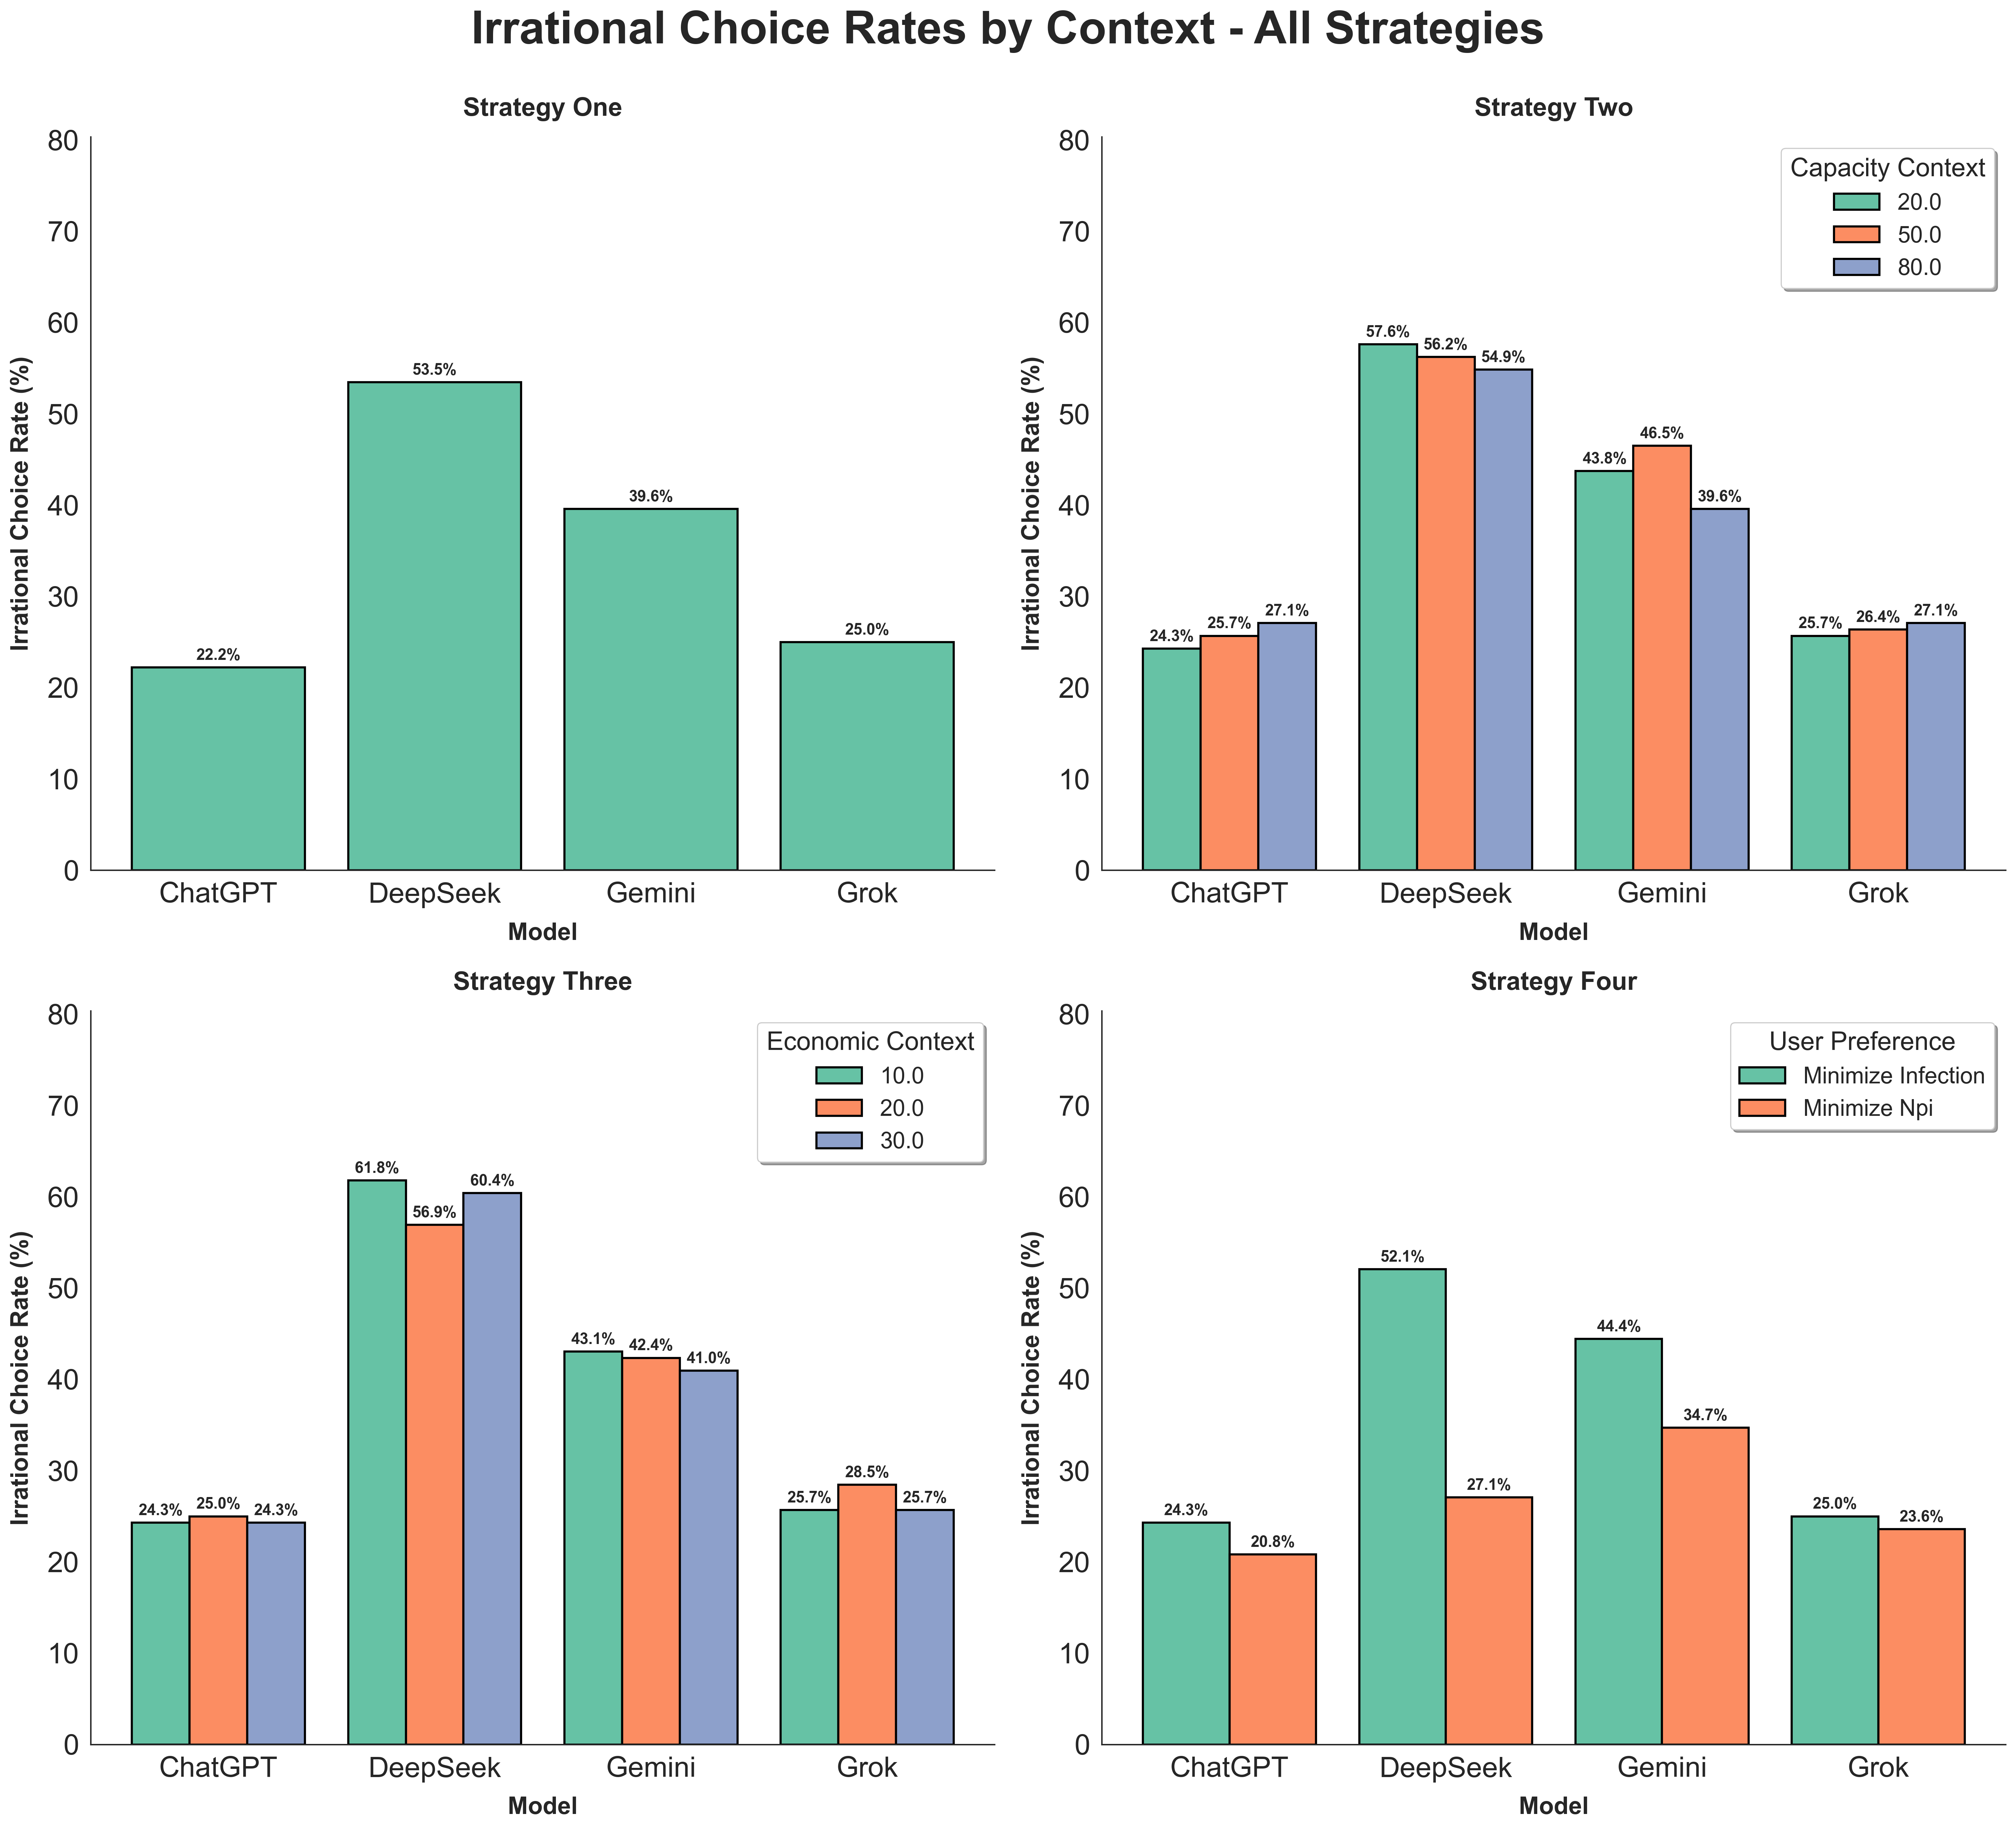

In [2339]:

# Generate combined 4-panel grouped plot
plot_combined_grouped_contexts(context_breakdown, save_figure=False)

### Figure 3: NPI-Infection Correlation Graph

##### Pre-Processing + Function Definition

In [2340]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


In [2341]:

# Set publication-ready style
sns.set_style("white")
sns.set_context("paper", font_scale=1.8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 300


In [2342]:

def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    
    strategy_lower = strategy_name.lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    
    return 0


In [2343]:

def calculate_npi_preference_rate(df):
    """
    Calculate the percentage of times npi_preference > 0 for each infection_preference value.
    """
    results = []
    
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    
    for strategy in strategies:
        strategy_data = df[df['strategy'] == strategy].copy()
        
        # Check if required columns exist
        if 'infection_preference' not in strategy_data.columns or 'npi_preference' not in strategy_data.columns:
            continue
        
        # Group by infection_preference and calculate percentage where npi_preference > 0
        grouped = strategy_data.groupby('infection_preference').apply(
            lambda x: pd.Series({
                'npi_positive_rate': (x['npi_preference'] > 0).mean() * 100,
                'count': len(x)
            })
        ).reset_index()
        
        grouped['strategy'] = strategy
        results.append(grouped)
    
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


In [2344]:

# Calculate NPI preference rates
abs_inf_df = results_df.copy()
abs_inf_df['infection_preference'] = abs_inf_df['infection_preference'].abs()
npi_preference_data = calculate_npi_preference_rate(abs_inf_df)

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_98680/763285521.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grouped = strategy_data.groupby('infection_preference').apply(
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_98680/763285521.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grouped = strategy_data.groupby('infection_preference').apply(
/var/folders/6n/bdd22kl9663flsjbqxx1cg

In [2345]:

def plot_individual_npi_preference(npi_data, save_figures=False):
    """
    Create individual bar plots for each strategy showing NPI preference rates 
    by infection preference (treated as categorical).
    """
    strategies = sorted(npi_data['strategy'].unique(), key=extract_strategy_number)
    
    for strategy in strategies:
        strategy_data = npi_data[npi_data['strategy'] == strategy].copy()
        
        # Sort by infection_preference
        strategy_data = strategy_data.sort_values('infection_preference')
        
        # Convert infection_preference to categorical for better visualization
        categories = [str(x) for x in sorted(strategy_data['infection_preference'].unique())]
        strategy_data['infection_pref_cat'] = strategy_data['infection_preference'].astype(str)
        
        fig, ax = plt.subplots(figsize=(14, 8))
        
        # Create bar plot with categorical x-axis
        x_positions = np.arange(len(strategy_data))
        bars = ax.bar(
            x_positions,
            strategy_data['npi_positive_rate'],
            color=sns.color_palette("Set2")[0],
            edgecolor='black',
            linewidth=1.8,
            width=0.7
        )
        
        # Set x-axis labels
        ax.set_xticks(x_positions)
        ax.set_xticklabels(strategy_data['infection_pref_cat'], fontsize=16)
        
        # Add value labels on bars
        for bar, val in zip(bars, strategy_data['npi_positive_rate']):
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2., 
                height + 1,
                f'{val:.1f}%',
                ha='center', 
                va='bottom',
                fontsize=14,
                fontweight='bold'
            )
        
        # Formatting
        ax.set_xlabel('Infection Preference', fontsize=18, fontweight='bold', labelpad=12)
        ax.set_ylabel('NPI Preference > 0 (%)', fontsize=18, fontweight='bold', labelpad=12)
        
        # Format strategy name for title
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(f'{strategy_title}', fontsize=20, fontweight='bold', pad=20)
        
        # Set y-axis limits
        ax.set_ylim(0, min(100, strategy_data['npi_positive_rate'].max() * 1.2))
        
        # Adjust ticks
        ax.tick_params(axis='y', labelsize=16)
        
        # Remove spines
        sns.despine(ax=ax)
        
        plt.tight_layout()
        
        if save_figures:
            plt.savefig(f'npi_preference_{strategy}.png', 
                       dpi=300, bbox_inches='tight', facecolor='white')
        
        plt.show()


In [2346]:

# Generate individual NPI preference plots
# plot_individual_npi_preference(npi_preference_data, save_figures=False)


In [2347]:

def plot_combined_npi_preference(npi_data, save_figure=False):
    """
    Create a combined 4-panel figure showing NPI preference rates for all strategies.
    """
    strategies = sorted(npi_data['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    
    # Determine layout
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 9 * n_rows))
    
    # Flatten axes
    if n_strategies == 1:
        axes = np.array([axes])
    elif n_strategies == 2:
        axes = np.array(axes)
    else:
        axes = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes[idx]
        strategy_data = npi_data[npi_data['strategy'] == strategy].copy()
        
        # Sort by infection_preference
        strategy_data = strategy_data.sort_values('infection_preference')
        
        # Convert infection_preference to categorical
        strategy_data['infection_pref_cat'] = strategy_data['infection_preference'].astype(str)
        
        # Create bar plot with categorical x-axis
        x_positions = np.arange(len(strategy_data))
        bars = ax.bar(
            x_positions,
            strategy_data['npi_positive_rate'],
            color=sns.color_palette("Set2")[0],
            edgecolor='black',
            linewidth=1.8,
            width=0.7
        )
        
        # Set x-axis labels
        ax.set_xticks(x_positions)
        ax.set_xticklabels(strategy_data['infection_pref_cat'], fontsize=15)
        
        # Add value labels on bars
        for bar, val in zip(bars, strategy_data['npi_positive_rate']):
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2., 
                height + 1,
                f'{val:.1f}%',
                ha='center', 
                va='bottom',
                fontsize=18,
                fontweight='bold'
            )
        
        # Formatting
        ax.set_xlabel('Infection Difference', fontsize=18, fontweight='bold', labelpad=10)
        ax.set_ylabel('Business Closure Preference (%)', fontsize=18, fontweight='bold', labelpad=10)
        
        # Format strategy name for title
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(strategy_title, fontsize=20, fontweight='bold', pad=15)
        
        # Set y-axis limits
        ax.set_ylim(0, min(100, npi_data['npi_positive_rate'].max() * 1.2))
        
        # Adjust ticks
        ax.tick_params(axis='y', labelsize=18)
        ax.tick_params(axis='x', labelsize=18)
        
        # Remove spines
        sns.despine(ax=ax)
    
    # Hide unused subplots
    for idx in range(n_strategies, len(axes)):
        axes[idx].set_visible(False)
    
    # Overall title
    fig.suptitle('NPI Preference Rates by Infection Preference - All Strategies', 
                 fontsize=32, fontweight='bold', y=0.995)
    
    plt.tight_layout()
    
    if save_figure:
        plt.savefig('npi_preference_combined.png', 
                   dpi=300, bbox_inches='tight', facecolor='white')
    
    plt.show()


##### Final Output

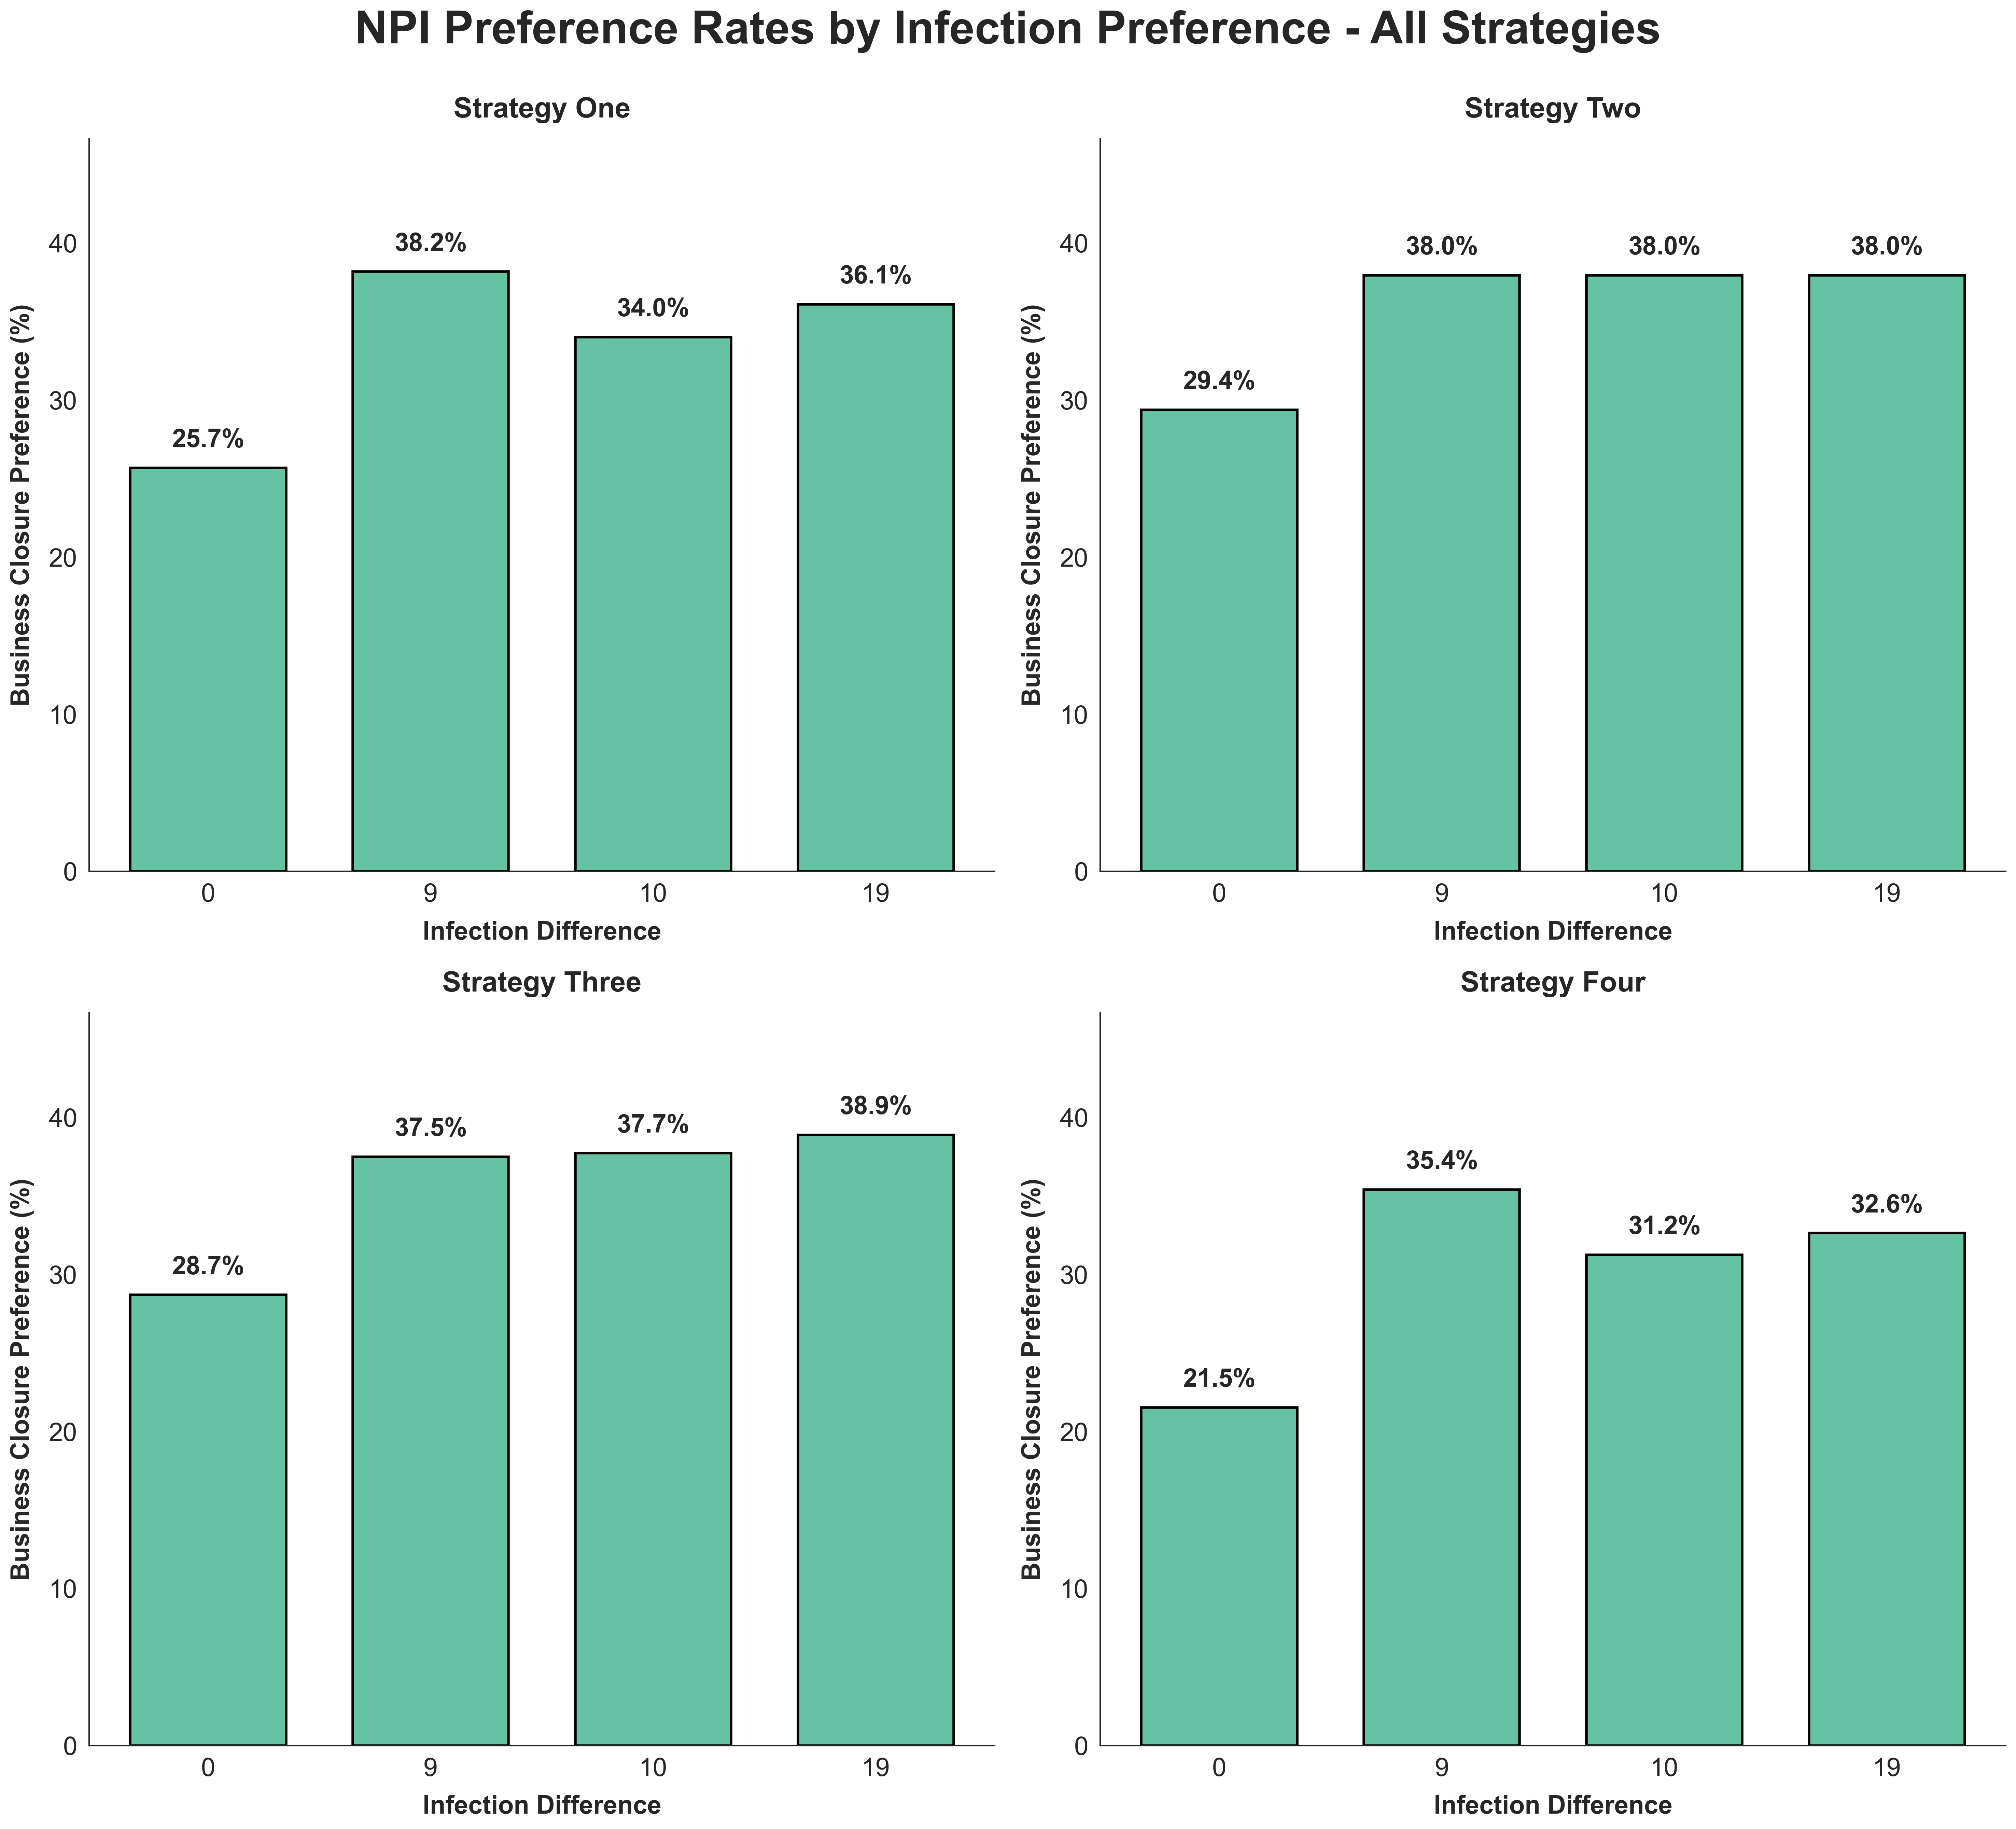

In [2348]:
# Generate combined 4-panel plot
plot_combined_npi_preference(npi_preference_data, save_figure=False)


### Figure 4: Mean Infection Preference

##### Pre-Processing + Function Definition

In [2349]:
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from scipy import stats
import pandas as pd
import numpy as np


In [2350]:

# Set publication-ready style
sns.set_style("white")
sns.set_context("paper", font_scale=1.8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 300


In [2351]:

def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    
    strategy_lower = strategy_name.lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    
    return 0


In [2352]:

def get_context_column(strategy_name):
    """Return the appropriate context column name for each strategy."""
    strategy_num = extract_strategy_number(strategy_name)
    
    context_mapping = {
        2: 'capacity_context',
        3: 'economic_context',
        4: 'user_preference_type'
    }
    
    return context_mapping.get(strategy_num, None)


In [2353]:

def get_legend_title(context_col):
    """Return a formatted legend title based on the context column name."""
    if not context_col:
        return None
    
    title_mapping = {
        'capacity_context': 'Capacity Context',
        'economic_context': 'Economic Context',
        'user_preference_type': 'User Preference'
    }
    
    return title_mapping.get(context_col, context_col.replace('_', ' ').title())


In [2354]:

def wrap_label(text, max_len=20):
    """Wrap text labels for better readability."""
    text = str(text)
    return '\n'.join(textwrap.wrap(text, width=max_len))


In [2355]:

def calculate_errorbar_data(df, response_col, context_cols, use_percentage=False):
    """Calculate means and confidence intervals for errorbar plots."""
    grouped = df.groupby(context_cols)[response_col]
    
    plot_data = []
    for name, group in grouped:
        if len(group) > 0:
            data = group.values
            if use_percentage:
                data = data * 100
            
            mean_val = data.mean()
            ci = stats.t.interval(
                0.95,
                len(data) - 1,
                loc=mean_val,
                scale=stats.sem(data)
            )
            
            record = {}
            if isinstance(name, tuple):
                for i, col in enumerate(context_cols):
                    record[col] = name[i]
            else:
                record[context_cols[0]] = name
            
            record['mean'] = mean_val
            record['ci_lower'] = mean_val - ci[0]
            record['ci_upper'] = ci[1] - mean_val
            record['n'] = len(data)
            
            plot_data.append(record)
    
    return pd.DataFrame(plot_data)


In [2356]:

def plot_individual_errorbar(df, response_col, parameter_col, use_percentage=False, save_figures=False):
    """
    Create individual errorbar plots for each strategy.
    Automatically includes context variables based on strategy.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame with data
    response_col : str
        Column name for the response variable (e.g., 'npi_preference')
    parameter_col : str
        Single parameter column (e.g., 'infection_preference')
    use_percentage : bool
        Whether to convert to percentage
    save_figures : bool
        Whether to save figures to disk
    """
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    unit = '%' if use_percentage else ''
    
    for strategy in strategies:
        strategy_data = df[df['strategy'] == strategy].copy()
        strategy_num = extract_strategy_number(strategy)
        
        # Get context column for this strategy
        context_col = get_context_column(strategy)
        
        # Determine grouping columns
        if context_col and context_col in strategy_data.columns:
            # Multiple grouping: parameter + context
            group_cols = [parameter_col, context_col]
        else:
            # Single grouping: just parameter (Strategy 1)
            group_cols = [parameter_col]
        
        # Calculate overall mean for this strategy
        overall_mean = strategy_data[response_col].mean()
        if use_percentage:
            overall_mean = overall_mean * 100
        
        # Calculate errorbar data
        plot_df = calculate_errorbar_data(strategy_data, response_col, group_cols, use_percentage)
        
        if len(plot_df) == 0:
            continue
        
        fig, ax = plt.subplots(figsize=(14, 8))
        
        # Single grouping (Strategy 1) - simple horizontal errorbar plot
        if len(group_cols) == 1:
            # Sort by mean
            plot_df = plot_df.sort_values('mean', ascending=True)
            
            y_positions = range(1, len(plot_df) + 1)
            
            ax.errorbar(
                plot_df['mean'],
                y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o',
                markersize=12,
                markerfacecolor=sns.color_palette("Set2")[0],
                markeredgecolor='black',
                markeredgewidth=1.5,
                ecolor='black',
                elinewidth=2.0,
                capsize=6,
                capthick=2
            )
            
            # Overall mean line
            ax.axvline(
                overall_mean,
                color='red',
                linestyle='--',
                linewidth=2.5,
                alpha=0.7,
                label=f'Mean = {overall_mean:.2f}{unit}'
            )
            
            # Labels
            wrapped_labels = [wrap_label(str(val)) for val in plot_df[parameter_col]]
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(wrapped_labels, fontsize=16)
            
            ax.set_ylim(0.5, len(plot_df) + 0.5)
            
        # Multiple grouping (Strategies 2, 3, 4) - grouped errorbar plot
        else:
            primary_col = parameter_col
            secondary_col = context_col
            
            primary_values = sorted(
                plot_df[primary_col].unique(),
                key=lambda x: plot_df[plot_df[primary_col] == x]['mean'].mean(),
                reverse=True
            )
            secondary_values = sorted(plot_df[secondary_col].unique())
            
            colors = sns.color_palette("Set2", len(secondary_values))
            
            group_spacing = 1.0
            bar_height = 0.7
            bar_spacing = bar_height / max(1, len(secondary_values))
            
            y_positions = {}
            current_y = 1.0
            for primary_val in primary_values:
                y_positions[primary_val] = current_y
                current_y += group_spacing
            
            for i, secondary_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == secondary_val]
                
                y_coords = []
                means = []
                ci_lowers = []
                ci_uppers = []
                
                for primary_val in primary_values:
                    row = subset[subset[primary_col] == primary_val]
                    if len(row) > 0:
                        y_offset = (i - len(secondary_values) / 2 + 0.5) * bar_spacing
                        y_coords.append(y_positions[primary_val] + y_offset)
                        means.append(row['mean'].values[0])
                        ci_lowers.append(row['ci_lower'].values[0])
                        ci_uppers.append(row['ci_upper'].values[0])
                
                ax.errorbar(
                    means,
                    y_coords,
                    xerr=[ci_lowers, ci_uppers],
                    fmt='o',
                    markersize=10,
                    markerfacecolor=colors[i],
                    markeredgecolor='black',
                    markeredgewidth=1.5,
                    ecolor='black',
                    elinewidth=2.0,
                    capsize=6,
                    capthick=2,
                    label=str(secondary_val).replace('_', ' ').title()
                )
            
            # Overall mean line
            ax.axvline(
                overall_mean,
                color='red',
                linestyle='--',
                linewidth=2.5,
                alpha=0.7,
                label=f'Mean = {overall_mean:.2f}{unit}',
                zorder=0
            )
            
            wrapped_labels = [wrap_label(str(val)) for val in primary_values]
            ax.set_yticks([y_positions[val] for val in primary_values])
            ax.set_yticklabels(wrapped_labels, fontsize=16)
            
            # Add legend with context title
            legend_title = get_legend_title(context_col)
            ax.legend(
                fontsize=14,
                title=legend_title,
                title_fontsize=15,
                loc='best',
                frameon=True,
                fancybox=True,
                shadow=True
            )
            
            ax.set_ylim(0.5, current_y - group_spacing + 0.5)
        
        # Common formatting
        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Mean with 95% CI)'
        ax.set_xlabel(xlabel, fontsize=18, fontweight='bold', labelpad=12)
        
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(strategy_title, fontsize=20, fontweight='bold', pad=20)
        
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        
        sns.despine(ax=ax)
        
        plt.tight_layout()
        
        if save_figures:
            plt.savefig(f'{response_col}_{strategy}_errorbar.png', 
                       dpi=300, bbox_inches='tight', facecolor='white')
        
        plt.show()


In [2357]:

def plot_combined_errorbar(df, response_col, parameter_col, use_percentage=False, save_figure=False):
    """
    Create a combined 4-panel errorbar plot for all strategies.
    Automatically includes context variables based on strategy.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame with data
    response_col : str
        Column name for the response variable
    parameter_col : str
        Single parameter column
    use_percentage : bool
        Whether to convert to percentage
    save_figure : bool
        Whether to save figure to disk
    """
    strategies = sorted(df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies)
    unit = '%' if use_percentage else ''
    
    # Determine layout
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 9 * n_rows))
    
    # Flatten axes
    if n_strategies == 1:
        axes = np.array([axes])
    elif n_strategies == 2:
        axes = np.array(axes)
    else:
        axes = axes.flatten()
    
    for idx, strategy in enumerate(strategies):
        ax = axes[idx]
        strategy_data = df[df['strategy'] == strategy].copy()
        strategy_num = extract_strategy_number(strategy)
        
        # Get context column for this strategy
        context_col = get_context_column(strategy)
        
        # Determine grouping columns
        if context_col and context_col in strategy_data.columns:
            group_cols = [parameter_col, context_col]
        else:
            group_cols = [parameter_col]
        
        # Calculate overall mean
        overall_mean = strategy_data[response_col].mean()
        if use_percentage:
            overall_mean = overall_mean * 100
        
        # Calculate errorbar data
        plot_df = calculate_errorbar_data(strategy_data, response_col, group_cols, use_percentage)
        
        if len(plot_df) == 0:
            continue
        
        # Single grouping (Strategy 1)
        if len(group_cols) == 1:
            plot_df = plot_df.sort_values('mean', ascending=True)
            
            y_positions = range(1, len(plot_df) + 1)
            
            ax.errorbar(
                plot_df['mean'],
                y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o',
                markersize=10,
                markerfacecolor=sns.color_palette("Set2")[0],
                markeredgecolor='black',
                markeredgewidth=1.5,
                ecolor='black',
                elinewidth=1.8,
                capsize=5,
                capthick=1.8
            )
            
            ax.axvline(overall_mean, color='red', linestyle='--', linewidth=2, alpha=0.7)
            
            wrapped_labels = [wrap_label(str(val), max_len=15) for val in plot_df[parameter_col]]
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(wrapped_labels, fontsize=14)
            ax.set_ylim(0.5, len(plot_df) + 0.5)
            
        # Multiple grouping (Strategies 2, 3, 4)
        else:
            primary_col = parameter_col
            secondary_col = context_col
            
            primary_values = sorted(
                plot_df[primary_col].unique(),
                key=lambda x: plot_df[plot_df[primary_col] == x]['mean'].mean(),
                reverse=True
            )
            secondary_values = sorted(plot_df[secondary_col].unique())
            
            colors = sns.color_palette("Set2", len(secondary_values))
            
            group_spacing = 1.0
            bar_height = 0.7
            bar_spacing = bar_height / max(1, len(secondary_values))
            
            y_positions = {}
            current_y = 1.0
            for primary_val in primary_values:
                y_positions[primary_val] = current_y
                current_y += group_spacing
            
            for i, secondary_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == secondary_val]
                
                y_coords = []
                means = []
                ci_lowers = []
                ci_uppers = []
                
                for primary_val in primary_values:
                    row = subset[subset[primary_col] == primary_val]
                    if len(row) > 0:
                        y_offset = (i - len(secondary_values) / 2 + 0.5) * bar_spacing
                        y_coords.append(y_positions[primary_val] + y_offset)
                        means.append(row['mean'].values[0])
                        ci_lowers.append(row['ci_lower'].values[0])
                        ci_uppers.append(row['ci_upper'].values[0])
                
                ax.errorbar(
                    means,
                    y_coords,
                    xerr=[ci_lowers, ci_uppers],
                    fmt='o',
                    markersize=8,
                    markerfacecolor=colors[i],
                    markeredgecolor='black',
                    markeredgewidth=1.2,
                    ecolor='black',
                    elinewidth=1.5,
                    capsize=4,
                    capthick=1.5,
                    label=str(secondary_val).replace('_', ' ').title()
                )
            
            ax.axvline(overall_mean, color='red', linestyle='--', linewidth=2, alpha=0.7, zorder=0)
            
            wrapped_labels = [wrap_label(str(val), max_len=15) for val in primary_values]
            ax.set_yticks([y_positions[val] for val in primary_values])
            ax.set_yticklabels(wrapped_labels, fontsize=20)
            ax.set_ylim(0.5, current_y - group_spacing + 0.5)
            
            # Add legend with context title
            legend_title = get_legend_title(context_col)
            ax.legend(
                fontsize=18,
                title=legend_title,
                title_fontsize=18,
                loc='best',
                frameon=True,
                fancybox=True,
                shadow=True
            )
        
        # Common formatting
        strategy_title = strategy.replace('_', ' ').title()
        ax.set_title(strategy_title, fontsize=20, fontweight='bold', pad=15)
        
        xlabel = f'{response_col.replace("_", " ").title()} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col.replace("_", " ").title()} (%)'
        ax.set_xlabel(xlabel, fontsize=20, fontweight='bold', labelpad=10)
        
        ax.tick_params(axis='x', labelsize=20)
        ax.tick_params(axis='y', labelsize=20)
        
        sns.despine(ax=ax)
    
    # Hide unused subplots
    for idx in range(n_strategies, len(axes)):
        axes[idx].set_visible(False)
    
    # Overall title
    fig.suptitle(f'{response_col.replace("_", " ").title()} by {parameter_col.replace("_", " ").title()} - All Strategies', 
                 fontsize=32, fontweight='bold', y=0.995)
    
    plt.tight_layout()
    
    if save_figure:
        plt.savefig(f'{response_col}_combined_errorbar.png', 
                   dpi=300, bbox_inches='tight', facecolor='white')
    
    plt.show()


##### Final Output

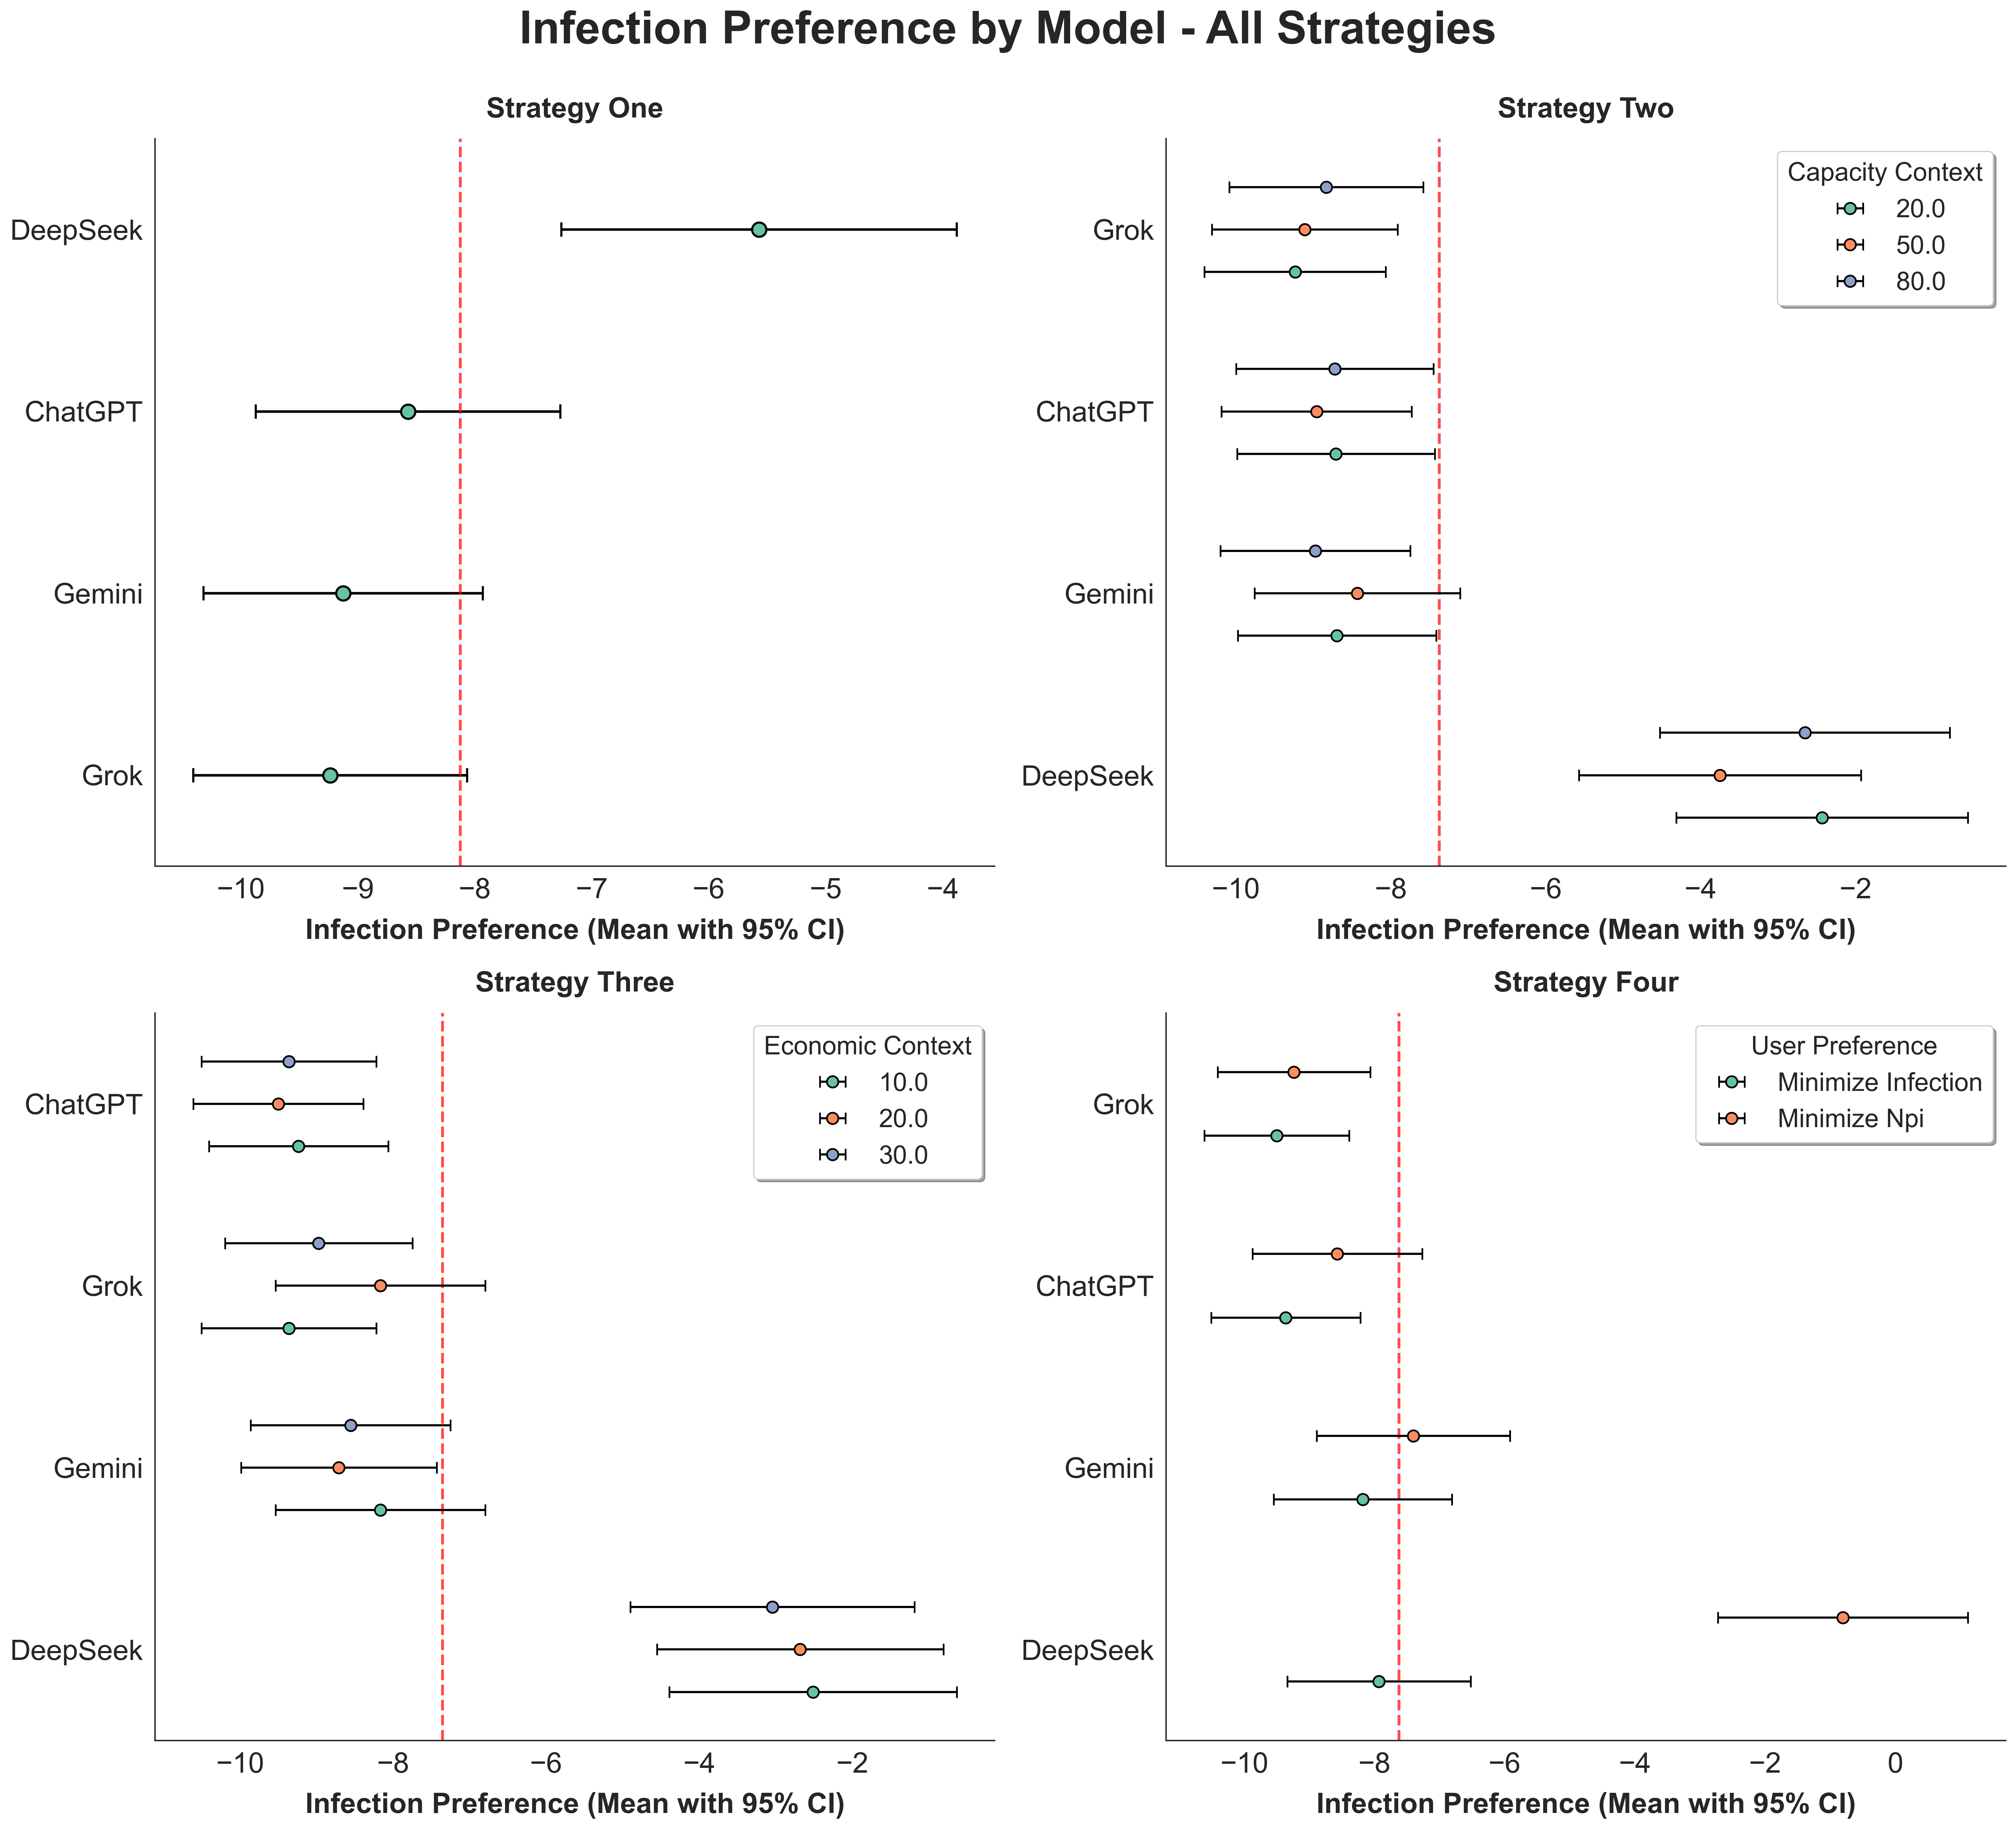

In [2358]:
plot_combined_errorbar(results_df, 'infection_preference', 'model', use_percentage=False)

### Figure 5: Mean NPI Preference

##### Pre-Processing + Function Definition

##### Final Output

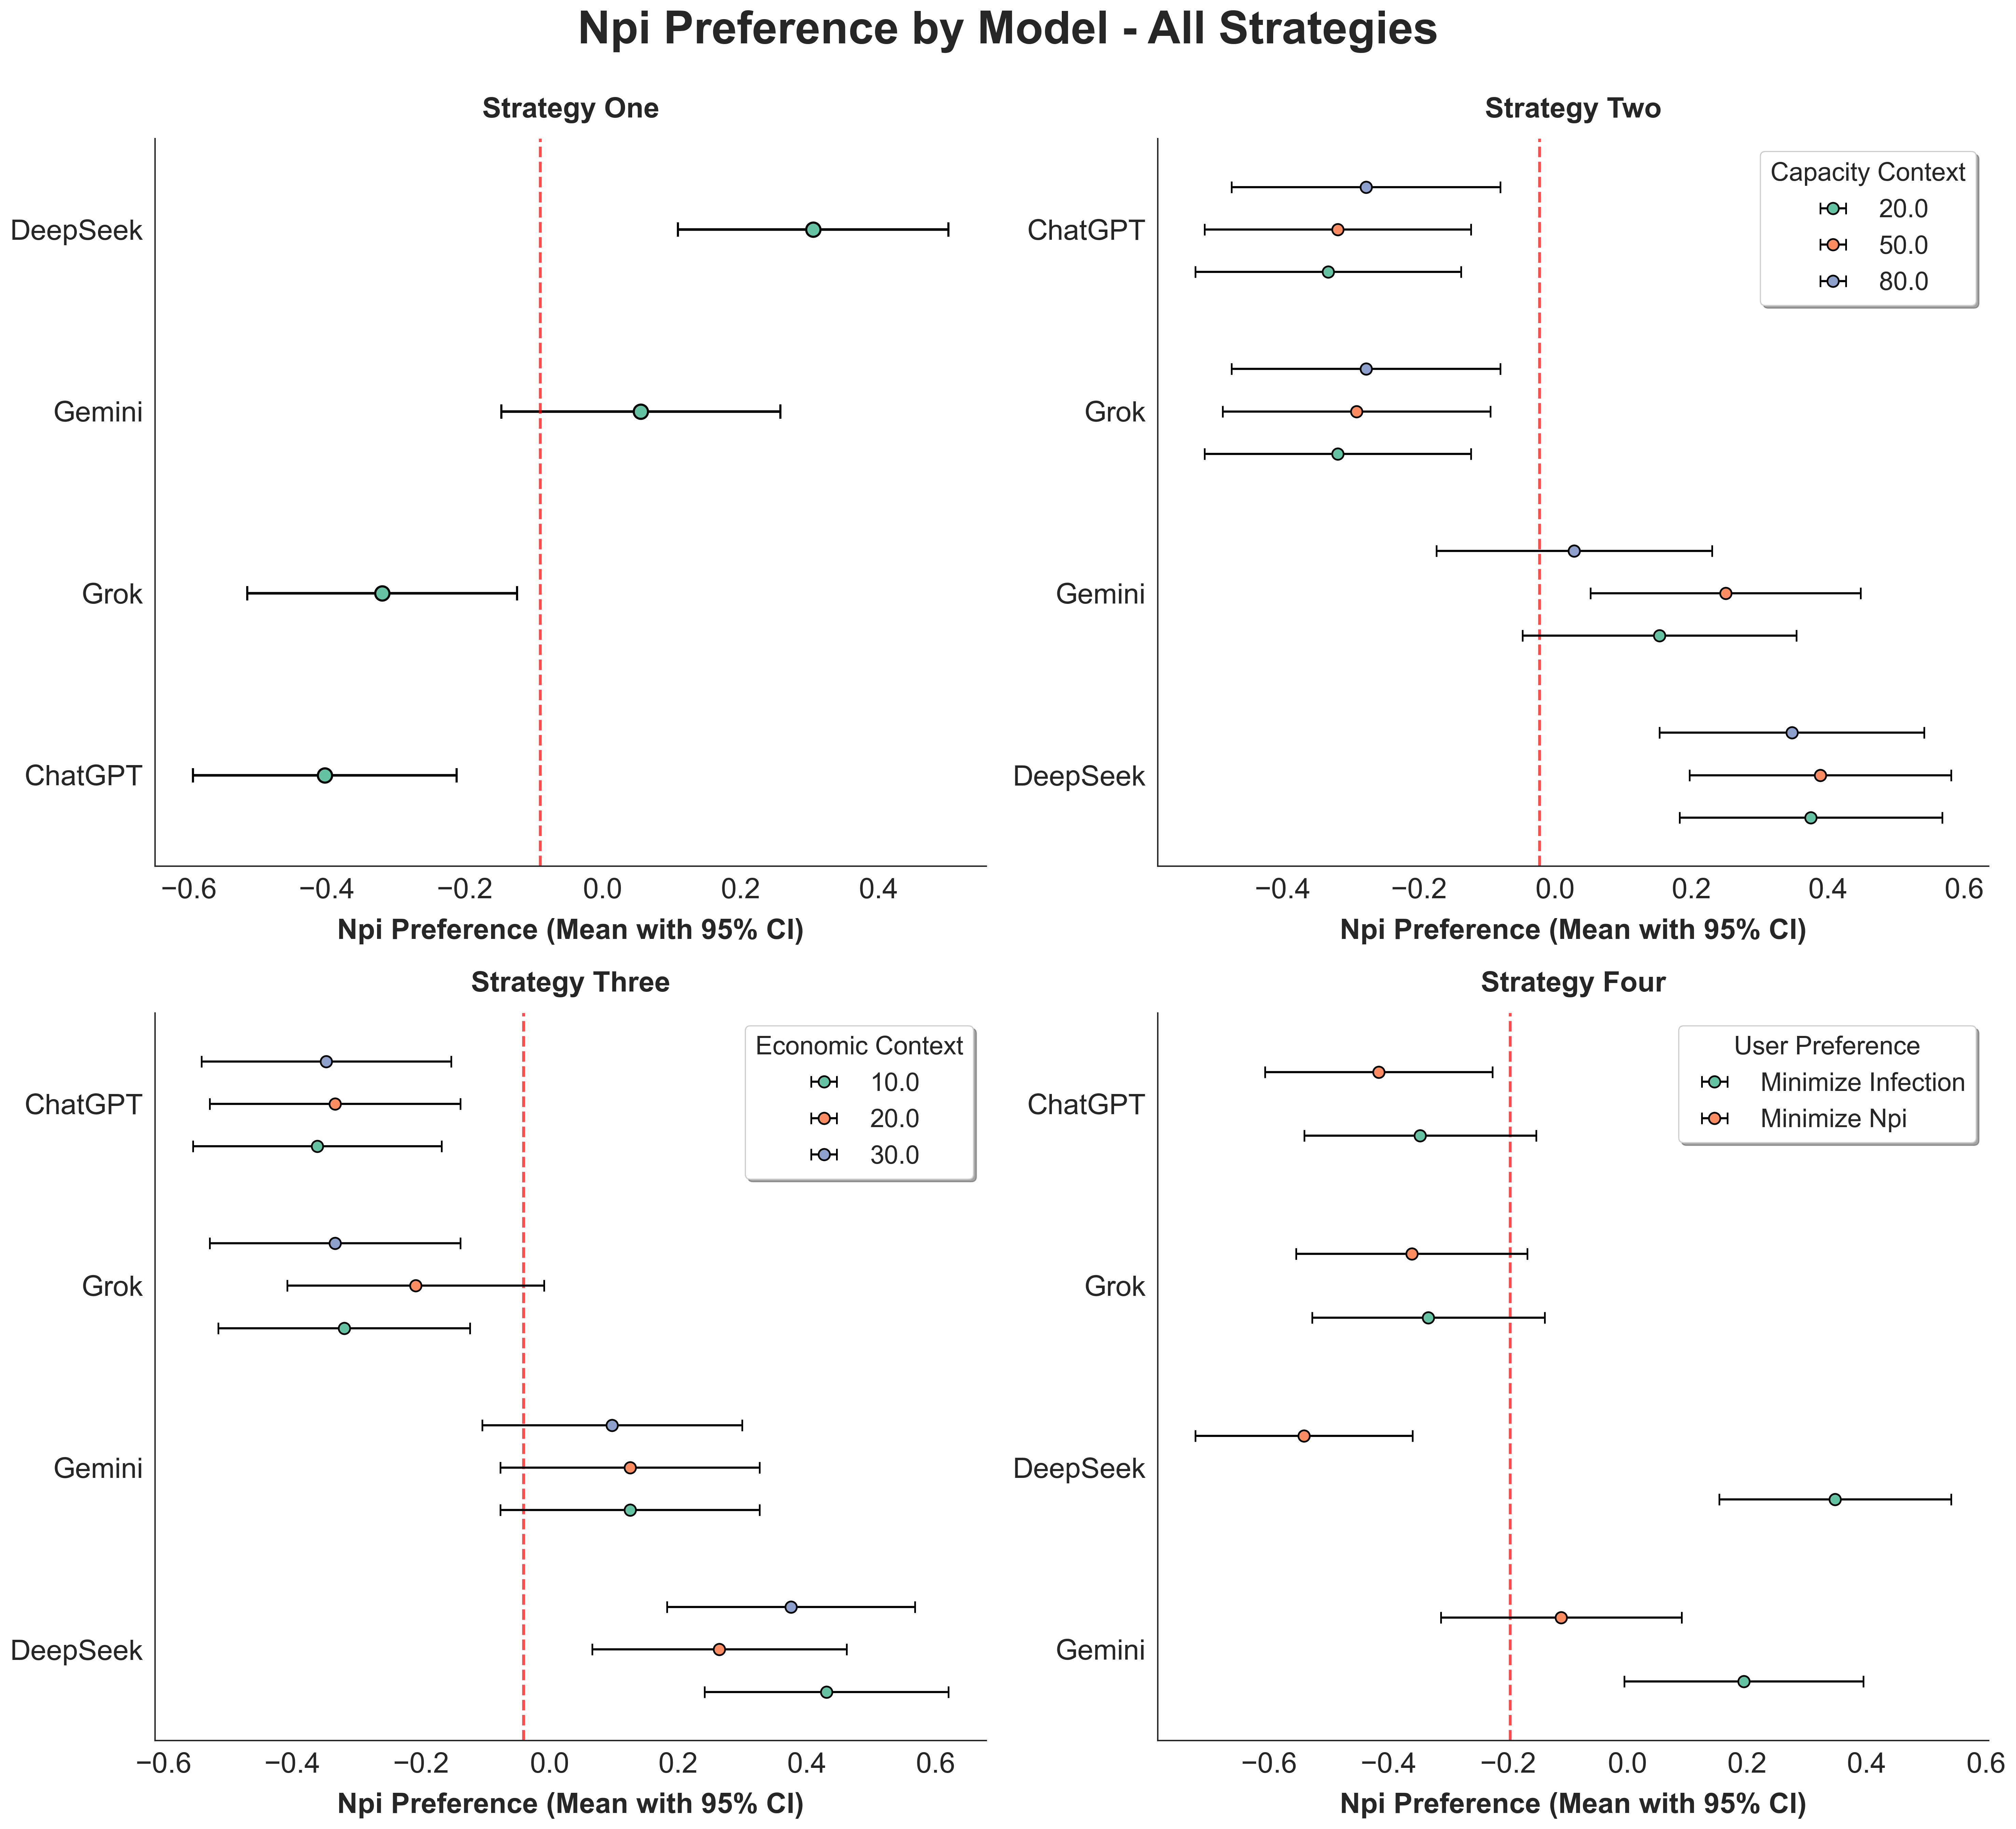

In [2359]:
plot_combined_errorbar(results_df, 'npi_preference', 'model', use_percentage=False)

### Figure 6

##### Pre-Processing + Function Definition

##### Final Output